# Can physical activity participation information improve predictions of later chronic pain?
## A logistic regression case study using NLSY97 survey data

### Governing Question

How much can including physical activity participation information improve the prediction of chronic pain beyond age and general health alone?

### Indended Audience

Students, researchers, or anyone exploring relationships between general health, physical activity, and later chronic pain. Note that this study is not meant to be used for medical diagnosis. 

### Study Overview

Using data from the National Longitudinal Survey of Youth 1997 (NLSY97), which is a longitudinal study that follows Americans born between 1980-1984, I investigate whether physical activity participation information collected in a 2015-2016 (Round 17) interview helps predict later self-reported chronic pain in a 2019-2020 (Round 19) follow-up.

This case study will use 7 predictor columns: 4 baseline health measurements and 3 physical activity measurements: participation in vigorous, light/moderate, and muscle-strengthening activity.

I compare two logistic regression models: one using age, self-rated health, and work limitation features and another that also includes physical activity participation. A third model, the Dummy Classifier, provides a benchmark for comparison.

| Model | Predictors | Purpose |
|--|--|--|
| Dummy Classifier | None | Establishes the majority-class benchmark |
| Model A: Baseline | Age, self-rated health, and two health-related work limitations | Predicts chronic pain without physical activity information |
| Model B: Extended	| Model A's features plus physical activity participation | Test the added predictive value of including physical activity information |

### Roadmap and Outline

1. Prepare the data: Select eligible respondents, handle missing values in the dataset, and encode categorical variables
2. Split the data: Create training (60%), validation (15%), and test (25%) sets
3. Train the models: Fit the Dummy Classifier and two logistic regression models
4. Evaluate performance: Compare models using balanced accuracy and other classification metrics
5. Interpret results: Determine whether adding physical activity improves prediction and discuss the limitations of this study

## 1. Investigation Contract

### 1.1 Study Design

The following table summarizes the main decisions of this study.

| Concept | Decision |
|---|---|
| Observation unit | One NLSY97 respondent (one row per person) |
| Population of interest | NLSY97 participants with usable information from both the 2015 and 2019 interview rounds |
| Prediction target | Whether a respondent reported chronic pain in 2019 (`1` = Yes, `0` = No) |
| Available information | Baseline Round 17 (2015–2016) age, self-rated health, work limitations, and physical activity participation |
| Learning task| Supervised binary classification: predicting chronic pain or no chronic pain |
| Type of investigation | Predictive and exploratory |
| Algorithm | Logistic regression |
| Value of a useful result | Helps determine whether physical activity participation provides useful predictive information beyond basic health information |
| Consequences of a wrong result | Incorrect predictions may miss respondents reporting pain or incorrectly identify those without pain. Misinterpreting the results can also lead to misleading health conclusions. |

### 1.2 Why Logistic Regression? 

Logistic regression is an algorithm that can estimate the probability of a binary outcome, such as chronic pain or no chronic pain. It is also relatively simple and easy to interpret, allowing me to examine how predictors relate to the estimated probability of chronic pain. Using the same algorithm for both models (Model A: Baseline and Model B: Extended) allows me to directly compare their performance and assess whether adding the additional information can improve prediction.

### 1.3 Non-goals

This study is meant only to investigate the relationship between physical activity, general health information, and chronic pain. It does not attempt to diagnose chronic pain, determine when the pain began, or establish whether physical activity can causes or prevent pain.

## 2. Data Provenance and Fitness for Purpose

### 2.1 Dataset Source

| Item | Description |
|---|---|
| Source | [National Longitudinal Survey of Youth 1997 (NLSY97)](https://www.nlsinfo.org/content/cohorts/nlsy97) |
| Owner | U.S. Bureau of Labor Statistics, National Longitudinal Surveys Program |
| Retrieval | Custom subset downloaded via NLS Investigator on November 14, 2026 |
| Access and Terms | Public-use survey data, follow the [NLS documentation](https://nlsinfo.org/) for citation and redistribution |
| Sample | 8,984 American individuals born between 1980 and 1984, first surveyed in 1997. The original sample also included additional Black and Hispanic respondents to improve representation. |
| Geographic scope | United States |
| Time period | Baseline: 2015 survey (2015–2016, Round 17); Outcome: 2019 survey (2019–2020, Round 19) |

View the dataset card for more information about the NLSY97 dataset: [DATASET_CARD.md](../docs/DATASET_CARD.md)


### 2.2 Variable Definitions

#### Predictor Variables

A. Baseline Health Features

| Variable | Type | Values |
|---|---|---|
| Age (`age_at_interview_2015`) | Numerical | Age in years at the baseline interview |
| General Health (`self_rated_health_2015`) | Ordinal | `1` = Excellent; `2` = Very good; `3` = Good; `4` = Fair; `5` = Poor |
| Health Limits Kind of Work (`health_limits_kind_of_work_2015`) | Binary | `0` = No limitation; `1` = Limitation |
| Health Limits Amount of Work (`health_limits_amount_of_work_2015`) | Binary | `0` = No limitation; `1` = Limitation |

B. Physical Activity Features

| Variable | Type | Values |
|---|---|---|
| Vigorous Activity Status (`vigorous_activity_status_2015`) | Categorical | `0` = Never; `1` = Participates; `2` = Unable |
| Light/Moderate Activity Status (`moderate_activity_status_2015`) | Categorical | `0` = Never; `1` = Participates; `2` = Unable |
| Muscle-Strengthening Activity Status (`strength_activity_status_2015`) | Categorical | `0` = Never; `1` = Participates; `2` = Unable |

#### Target Variable

| Variable | Type | Values |
|---|---|---|
| Chronic Pain (2019) (`chronic_pain_30d_2019`) | Binary target | `0` = No chronic pain; `1` = Chronic pain |

#### Identifier and Metadata Variables

These variables identify respondents or record interview timing. Note that they are not used as predictors.

| Variable | Type | Values |
|---|---|---|
| Respondent ID (`respondent_id`) | Identifier | Unique identifier for each participant |
| Baseline Interview Year (`interview_year_2015_round`) | Metadata | `2015` or `2016` |
| Follow-Up Interview Year (`interview_year_2019_round`) | Metadata | `2019` or `2020` |

#### Note: Special Response Codes

The NLSY97 dataset also uses negative values to identify missing, refused, skipped, or noninterview responses. In this study, these codes are not considered valid measurements of age, health, physical activity, or chronic pain and will be removed during data selection. 

| Code | Meaning |
|---|---|
| `-1` | Refusal |
| `-2` | Don't know |
| `-3` | Invalid skip |
| `-4` | Valid skip |
| `-5` | Noninterview |

### 2.3 Data Limitations and Scope 

This study uses the NLSY97 data to only consider physical activity participation, not exercise frequency or duration. The data also only follows Americans born between 1980 and 1984, meaning respondents are relatively close in age. This limits the model's ability to examine age differences, and the findings may not generalize to younger or older populations. Additionally, missing responses and excluding respondents who did not complete follow-up interviews may also introduce bias.

The following cell loads and inspects the dataset using my local configuration file (`student.toml`):

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from dsm_project.config import load_config
from dsm_project.data import load_project_dataset

# Locate and load the config file
CONFIG_PATH = Path("../configs/student.toml")
config = load_config(CONFIG_PATH)

# Load the dataset
dataset = load_project_dataset(config)

# Select classification task
task = dataset.tasks["classification"]

# Get the observations
frame = dataset.observations

# Get the variables from config
ID_COL = dataset.identifier
ALL_FEATURES = list(task.feature_columns)
TARGET = task.target_column

# Define interview year cols
INTERVIEW_YEARS = [
    "interview_year_2015_round",
    "interview_year_2019_round",
]

# Define the four baseline predictors
BASELINE_FEATURES = [
    "age_at_interview_2015",
    "self_rated_health_2015",
    "health_limits_kind_of_work_2015",
    "health_limits_amount_of_work_2015",
]

# Define the three relevant activity predictors
ACTIVITY_FEATURES = [
    "vigorous_activity_status_2015",
    "moderate_activity_status_2015",
    "strength_activity_status_2015",
]

# Group features together
SELECTED_FEATURES = BASELINE_FEATURES + ACTIVITY_FEATURES

# Check that all selected columns exist in the dataset
for col in INTERVIEW_YEARS + SELECTED_FEATURES + [TARGET]:
    assert col in frame.columns, f"Column not found: {col}"

assert ID_COL in frame.columns, "Identifier column is missing"
assert TARGET in frame.columns, "Target column is missing"

# Make a copy of the data (only the relevant columns)
data_subset = frame[[ID_COL] + INTERVIEW_YEARS + SELECTED_FEATURES + [TARGET]].copy()

# Display case study information
print("Dataset:", dataset.provenance.name)
print("Research task: Predict future chronic pain using baseline health and physical activity participation")
print("Target:", TARGET)
print("Num. predictors:", len(SELECTED_FEATURES))
print("Predictors:", SELECTED_FEATURES)

# Display subset information
print("Number of respondents:", len(data_subset))
print("Number of columns:", data_subset.shape[1])

# Preview the subset
display(data_subset.head())

# Check missing values and data types
check = pd.DataFrame({
    "Data type": data_subset[INTERVIEW_YEARS + SELECTED_FEATURES + [TARGET]].dtypes,
    "Missing (NaN)": data_subset[INTERVIEW_YEARS + SELECTED_FEATURES + [TARGET]].isna().sum(),
})
display(check)

Dataset: NLSY97 Physical Activity and Chronic Pain Subset
Research task: Predict future chronic pain using baseline health and physical activity participation
Target: chronic_pain_30d_2019
Num. predictors: 7
Predictors: ['age_at_interview_2015', 'self_rated_health_2015', 'health_limits_kind_of_work_2015', 'health_limits_amount_of_work_2015', 'vigorous_activity_status_2015', 'moderate_activity_status_2015', 'strength_activity_status_2015']
Number of respondents: 8984
Number of columns: 11


,respondent_id,interview_year_2015_round,interview_year_2019_round,age_at_interview_2015,self_rated_health_2015,health_limits_kind_of_work_2015,health_limits_amount_of_work_2015,vigorous_activity_status_2015,moderate_activity_status_2015,strength_activity_status_2015,chronic_pain_30d_2019
0,1,2016,-5,34,3,0,0,1,1,0,-5
1,2,2016,2019,33,2,0,0,0,0,0,0
2,3,-5,2019,-5,-5,-5,-5,-5,-5,-5,0
3,4,2015,2019,34,2,0,0,1,1,0,0
4,5,2015,2019,33,2,0,0,1,1,0,0


,Data type,Missing (NaN)
interview_year_2015_round,int64,0
interview_year_2019_round,int64,0
age_at_interview_2015,int64,0
self_rated_health_2015,int64,0
health_limits_kind_of_work_2015,int64,0
health_limits_amount_of_work_2015,int64,0
vigorous_activity_status_2015,int64,0
moderate_activity_status_2015,int64,0
strength_activity_status_2015,int64,0
chronic_pain_30d_2019,int64,0


We see there are no original missing values in the dataset, and the data types are appropriate for the features and target variable.

## 3. Purposeful exploration

### 3.1 Prepare the eligible cohort

The following cell selects participants who meet the eligibility requirements:
1. Completed both 2015 and 2019 interview rounds
2. Have a valid binary 2019 chronic pain response (`0` or `1`)

The number of respondants remaining at each stage are also displayed below.

In [2]:
# Selecting the valid responses
has_baseline = data_subset["interview_year_2015_round"].isin([2015, 2016])
has_followup = data_subset["interview_year_2019_round"].isin([2019, 2020])
has_valid_target = data_subset["chronic_pain_30d_2019"].isin([0, 1])

# Display counts at each stage
cohort_counts = pd.DataFrame({
    "Selection stage": [
        "Original rows", "Valid baseline interview",
        "Both interview rounds", "Both rounds + valid pain target"
    ],
    "Respondents": [
        len(data_subset), int(has_baseline.sum()),
        int((has_baseline & has_followup).sum()),
        int((has_baseline & has_followup & has_valid_target).sum()),
    ],
})
display(cohort_counts)

# Make a copy of the eligible dataset
eligible_dataset = data_subset.loc[
    has_baseline & has_followup & has_valid_target,
    [ID_COL] + INTERVIEW_YEARS + SELECTED_FEATURES + [TARGET]
].copy()

,Selection stage,Respondents
0,Original rows,8984
1,Valid baseline interview,7103
2,Both interview rounds,6402
3,Both rounds + valid pain target,6389


### 3.2 Clean Feature Values and Finalize Sample

In this section, I replace negative NLSY97 response codes (`-1` through `-5`) with `NaN` (missing values) and verify that the 19 predictor variables contain valid responses.

The following rules are applied:

1. **Age:** Between 30 and 36 years
2. **General health:** Integer values from `1` (Excellent) to `5` (Poor)
3. **Health-related work limitations:** `0` (No) or `1` (Yes)
4. **Physical activity participation:** `0` (Never), `1` (Participates), or `2` (Unable)


In [3]:
# Replace negative codes with NaN
for col in SELECTED_FEATURES:
    eligible_dataset[col] = eligible_dataset[col].mask(eligible_dataset[col] < 0)

# Specify specific columns
AGE_COL = BASELINE_FEATURES[0]
HEALTH_COL = BASELINE_FEATURES[1]
HEALTH_LIMITS_COLS = BASELINE_FEATURES[2:4]

# Cleaning features
eligible_dataset[AGE_COL] = eligible_dataset[AGE_COL].where(
    eligible_dataset[AGE_COL].between(30, 36)
)

eligible_dataset[HEALTH_COL] = eligible_dataset[HEALTH_COL].where(
    eligible_dataset[HEALTH_COL].isin([1, 2, 3, 4, 5])
)

for col in HEALTH_LIMITS_COLS:
    eligible_dataset[col] = eligible_dataset[col].where(
        eligible_dataset[col].isin([0, 1])
    )

for col in ACTIVITY_FEATURES:
    eligible_dataset[col] = eligible_dataset[col].where(
        eligible_dataset[col].isin([0, 1, 2])
    )

# Summary
missing_summary = pd.DataFrame({
    "Invalid/Missing": eligible_dataset[SELECTED_FEATURES].isna().sum(),
    "Percent missing (%)": (
        eligible_dataset[SELECTED_FEATURES].isna().mean() * 100
    ).round(2),
})

display(missing_summary)

,Invalid/Missing,Percent missing (%)
age_at_interview_2015,0,0.00
self_rated_health_2015,8,0.13
health_limits_kind_of_work_2015,18,0.28
health_limits_amount_of_work_2015,18,0.28
vigorous_activity_status_2015,34,0.53
moderate_activity_status_2015,80,1.25
strength_activity_status_2015,37,0.58


Since the invalid responses make up only a small proportion of the dataset, I choose to remove respondents missing any of the selected predictors. The resulting cohort will be my final sample.

In [4]:
# Number of respondents before removing missing predictors
print("Number of respondents before removing missing predictors:", len(eligible_dataset))

# Remove respondents missing any of the predictors
eligible_dataset = eligible_dataset.dropna(subset=SELECTED_FEATURES).copy()

# Number of respondents remaining
print("Number of respondents after removing missing predictors:", len(eligible_dataset))

# Confirm final cohort
print(f"\nFinal eligible cohort: {len(eligible_dataset):,}")

# Gates
assert eligible_dataset[ID_COL].is_unique 
assert eligible_dataset[TARGET].isin([0, 1]).all() 
assert eligible_dataset[AGE_COL].between(30, 36).all() 
assert eligible_dataset[HEALTH_COL].isin([1, 2, 3, 4, 5]).all() 
assert all(eligible_dataset[col].isin([0, 1]).all() for col in HEALTH_LIMITS_COLS)
assert all(eligible_dataset[col].isin([0, 1, 2]).all() for col in ACTIVITY_FEATURES)
assert eligible_dataset[SELECTED_FEATURES].notna().all().all() 


Number of respondents before removing missing predictors: 6389
Number of respondents after removing missing predictors: 6259

Final eligible cohort: 6,259


### 3.3 Inspect Chronic Pain Distribution

Before training the models, I examine the distribution of chronic pain responses in 2019. This helps determine how to evaluate the predictive performance of my models.

,Meaning,Respondents,Percent
0,No chronic pain,5590,89.31
1,Reported chronic pain,669,10.69


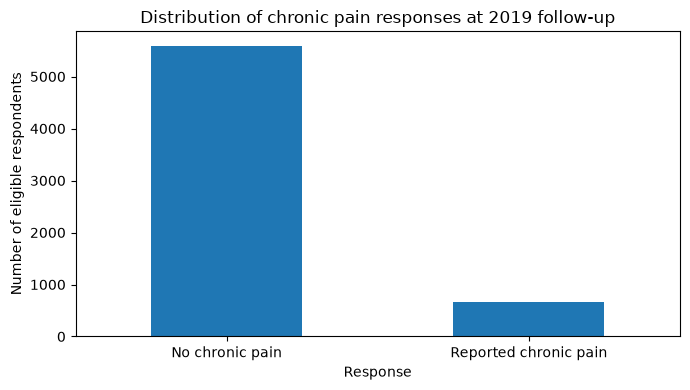

In [5]:
pain_counts = eligible_dataset[TARGET].value_counts().reindex([0, 1], fill_value=0)
pain_table = pd.DataFrame({
    "Meaning": ["No chronic pain", "Reported chronic pain"],
    "Respondents": pain_counts.to_numpy(),
    "Percent": (100 * pain_counts / pain_counts.sum()).round(2).to_numpy(),
}, index=[0, 1])
display(pain_table)

# Plotting the distribution of chronic pain responses
ax = pain_table.set_index("Meaning")["Respondents"].plot(kind="bar", figsize=(7, 4))
ax.set(title="Distribution of chronic pain responses at 2019 follow-up",
       xlabel="Response", ylabel="Number of eligible respondents")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Of the 6,259 eligible respondents, 10.69% reported chronic pain, while 89.31% did not. This shows that chronic pain is much less common in the dataset, which may make it more difficult for a model to learn to identify respondents who report pain.

### 3.4 Inspect Physical Activity Participation

I compare the distribution of the three activity participation variables. This shows how many respondents **never participate**, **participate**, or are **unable to participate** in each type of activity.

Number of respondents:


,Vigorous,Light/moderate,Muscle-strengthening
Never,1080,1198,2905
Participates,5106,5023,3282
Unable,73,38,72


Percent of respondents (%):


,Vigorous,Light/moderate,Muscle-strengthening
Never,17.26,19.14,46.41
Participates,81.58,80.25,52.44
Unable,1.17,0.61,1.15


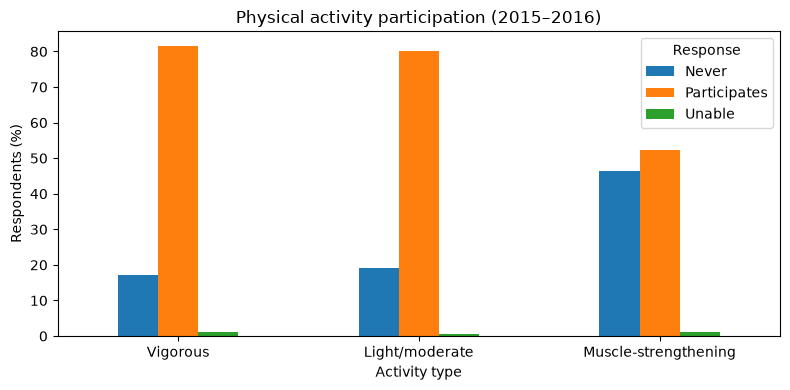

In [6]:
# Names to use in the table and chart
activity_labels = {
    "vigorous_activity_status_2015": "Vigorous",
    "moderate_activity_status_2015": "Light/moderate",
    "strength_activity_status_2015": "Muscle-strengthening",
}

# Count each response (0 = Never, 1 = Participates, 2 = Unable)
activity_counts = pd.DataFrame(index=["Never", "Participates", "Unable"])
activity_percent = pd.DataFrame(index=["Never", "Participates", "Unable"])

for column, label in activity_labels.items():
    counts = eligible_dataset[column].value_counts().reindex([0, 1, 2], fill_value=0)
    activity_counts[label] = counts.to_numpy()
    activity_percent[label] = (counts / len(eligible_dataset) * 100).round(2).to_numpy()

print("Number of respondents:")
display(activity_counts)

print("Percent of respondents (%):")
display(activity_percent)

# Compare participation categories across the three activities
ax = activity_percent.T.plot(kind="bar", figsize=(8, 4))
ax.set_title("Physical activity participation (2015–2016)")
ax.set_xlabel("Activity type")
ax.set_ylabel("Respondents (%)")
ax.legend(title="Response")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Participation was most common in vigorous activity (81.58%) and light/moderate activity (80.25%), compared with muscle-strengthening activity (52.44%). This suggests that muscle-strengthening participation differs substantially from the other two activity types and may provide distinct information when predicting chronic pain.

Additionally, very few respondents reported being unable to participate in any activity type (0.6–1.2%). Because these groups are relatively small, any conclusions involving them may be less reliable.

Since there are categorical differences in physical activity participation, it is also possible that they will lead to differences in chronic-pain outcomes. However, this relationship will need to be examined separately.

### 3.5 Inspect Health-Related Work Limitations

I examine the two health limitation variables to see how common work limitations were at the baseline interview. Each variable has two responses: `0` (No limitation) and `1` (Limitation).

Number of respondents:


,Kind of work,Amount of work
No limitation,5768,5828
Limitation,491,431


Percent of respondents (%):


,Kind of work,Amount of work
No limitation,92.16,93.11
Limitation,7.84,6.89


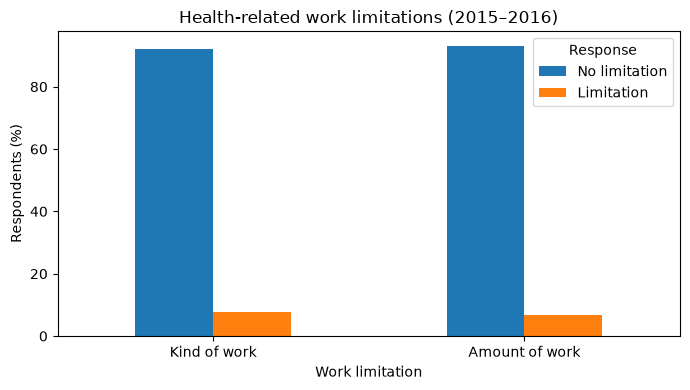

In [7]:
# Names to use in the table and chart
limitation_labels = {
    "health_limits_kind_of_work_2015": "Kind of work",
    "health_limits_amount_of_work_2015": "Amount of work",
}

# Count respondents with and without each limitation
limitation_counts = pd.DataFrame(index=["No limitation", "Limitation"])
limitation_percent = pd.DataFrame(index=["No limitation", "Limitation"])

for column, label in limitation_labels.items():
    counts = eligible_dataset[column].value_counts().reindex([0, 1], fill_value=0)
    limitation_counts[label] = counts.to_numpy()
    limitation_percent[label] = (counts / len(eligible_dataset) * 100).round(2).to_numpy()

print("Number of respondents:")
display(limitation_counts)

print("Percent of respondents (%):")
display(limitation_percent)

# Compare the two types of work limitations
ax = limitation_percent.T.plot(kind="bar", figsize=(7, 4))
ax.set_title("Health-related work limitations (2015–2016)")
ax.set_xlabel("Work limitation")
ax.set_ylabel("Respondents (%)")
ax.legend(title="Response")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

We see that the majority of respondants reported no limitation in both the kind and amount categories.

## 4. Experimental Boundaries and Baseline

### 4.1 Dividing the Dataset

To test whether the models can make accurate predictions for new respondants, the data is divided into three groups:

| Dataset | Percentage | Purpose |
|---|---:|---|
| **Training** | 60% | Used to teach the models patterns in the data |
| **Validation** | 15% | Used to compare models and help choose settings |
| **Testing** | 25% | Kept separate until the final evaluation (prevents data leakage) |

As seen in section 3.3, the proportion of no chronic pain responses far exceeds those with chronic pain. I will therefore use a **stratified random split**, which randomly assigns respondents while keeping approximately the same proportions of people in each category.

Because each person appears only once, I can directly split them without needing to worry about repeated individuals. All predictors come from the earlier 2015 round, so I am not using future responses to make predictions. This approach evaluates predictions for other respondents from the same cohort, rather than for an entirely new time period.

To prevent **data leakage**, I fit data-dependent preprocessing and model parameters using only the training data. I then apply the learned preprocessing rules to the validation and test sets. The test set will not influence model selection since it is untouched.

In [8]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Reserve 25% for testing
train_validation, test = train_test_split(
    eligible_dataset, test_size=0.25, random_state=438,
    stratify=eligible_dataset[TARGET],
)

# Split training and validation sets
train, validation = train_test_split(
    train_validation, test_size=0.20, random_state=438,
    stratify=train_validation[TARGET],
)

# Keep a record of the participant IDs
split_ids = {
    "train": set(train[ID_COL]),
    "validation": set(validation[ID_COL]),
    "test": set(test[ID_COL]),
}

# Gates
assert split_ids["train"].isdisjoint(split_ids["validation"])
assert split_ids["train"].isdisjoint(split_ids["test"])
assert split_ids["validation"].isdisjoint(split_ids["test"])
assert len(split_ids["train"] | split_ids["validation"] | split_ids["test"]) == len(eligible_dataset)

split_summary = pd.DataFrame({
    "Split": ["Train", "Validation", "Final test"],
    "Respondents": [len(x) for x in (train, validation, test)],
    "Pain Positive %": [round(100 * x[TARGET].mean(), 2)
                        for x in (train, validation, test)],
})
display(split_summary)

# TO DO: Move validated cohort/split behavior into tested functions under src/dsm_project/, then import them here.

,Split,Respondents,Pain Positive %
0,Train,3755,10.71
1,Validation,939,10.65
2,Final test,1565,10.67


### 4.2 Feature Encoding

**Model A (Baseline)** uses 4 health features: age (numerical), self-rated health (ordinal from `1` to `5`), and two health-related work limitations (binary `0` or `1`). I keep these features as they are.

**Model B (Extended)** uses the same 4 health features plus 3 physical activity participation variables. The activity codes represent categories rather than numerical amounts, so I convert each one into two binary indicators. The `0` (Never) response is the reference category.

| Activity Response | Participates | Unable |
|---|---:|---:|
| `0` — Never | 0 | 0 |
| `1` — Participates | 1 | 0 |
| `2` — Unable | 0 | 1 |

<br>

| Model | Original Predictors | Inputs After Encoding |
|---|---:|---:|
| **Model A (Baseline)** | 4 health features | 4 |
| **Model B (Extended)** | 4 health + 3 activity features | 10 |

In [9]:
# Model A
X_train_baseline = train[BASELINE_FEATURES].copy()
X_validation_baseline = validation[BASELINE_FEATURES].copy()

# Model B
# TO DO: Move to /src when complete
def encode_activity(data):
    features = data[BASELINE_FEATURES].copy()

    for col in ACTIVITY_FEATURES:
        features[col + "_participates"] = (data[col] == 1).astype(int)
        features[col + "_unable"] = (data[col] == 2).astype(int)

    return features

X_train_extended = encode_activity(train)
X_validation_extended = encode_activity(validation)

# Define target
y_train = train[TARGET].copy()
y_validation = validation[TARGET].copy()

# Check the number of model inputs
assert X_train_baseline.shape[1] == 4
assert X_train_extended.shape[1] == 10
assert X_train_extended.columns.tolist() == X_validation_extended.columns.tolist()

print("Model A training inputs:", X_train_baseline.shape)
print("Model B training inputs:", X_train_extended.shape)
display(X_train_extended.head())


Model A training inputs: (3755, 4)
Model B training inputs: (3755, 10)


,age_at_interview_2015,self_rated_health_2015,health_limits_kind_of_work_2015,health_limits_amount_of_work_2015,vigorous_activity_status_2015_participates,vigorous_activity_status_2015_unable,moderate_activity_status_2015_participates,moderate_activity_status_2015_unable,strength_activity_status_2015_participates,strength_activity_status_2015_unable
3071,31,2.0,0.0,0.0,1,0,1,0,0,0
3033,33,1.0,0.0,0.0,0,0,1,0,0,0
6387,31,2.0,0.0,0.0,1,0,1,0,1,0
3503,35,1.0,0.0,0.0,1,0,1,0,1,0
5011,32,4.0,1.0,1.0,1,0,1,0,1,0


### 4.3 Baseline and Evaluation Metric

I will compare both logistic regression models with a Dummy Classifier that always predicts the most common response. This serves as a simple benchmark.

My main evaluation metric is **balanced accuracy**. Because fewer respondents reported chronic pain, balanced accuracy gives equal weight to correctly identifying respondents with and without chronic pain.

$$
\text{Balanced accuracy} = \frac{1}{2}\left(\frac{TP}{TP+FN} + \frac{TN}{TN+FP}\right)
$$

Balanced accuracy ranges from `0` to `1`. A classifier that always predicts the majority class scores `0.5` when both classes are present. I use the validation set to compare models and leave the test set for the final evaluation.

In [10]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import balanced_accuracy_score

# The dummy model always predicts the most common training label
baseline_model = DummyClassifier(strategy="most_frequent")
baseline_model.fit(X_train_baseline, y_train)

# Evaluate the benchmark on the validation set
baseline_predictions = baseline_model.predict(X_validation_baseline)
baseline_score = balanced_accuracy_score(y_validation, baseline_predictions)

print(f"Dummy Classifier validation balanced accuracy: {baseline_score:.3f}")


Dummy Classifier validation balanced accuracy: 0.500


## 5. Mathematical Model: Logistic Regression

Logistic regression estimates the probability of a binary outcome. In this study, it predicts whether a respondent reports chronic pain in 2019 using information collected in 2015.

### 5.1 Model Inputs and Parameters

For each respondent $i$, the model uses the following notation:

| Symbol | Meaning |
|---|---|
| $n$ | Number of training respondents |
| $d$ | Number of numerical input features |
| $\boldsymbol x_i \in \mathbb{R}^d$ | Input features for respondent $i$ |
| $y_i \in \{0,1\}$ | Actual chronic-pain response (0 = No, 1 = Yes) |
| $\boldsymbol w \in \mathbb{R}^d$ | Feature weights learned during training |
| $b \in \mathbb{R}$ | Bias (intercept) learned during training |
| $z_i$ | Weighted sum of the inputs |
| $p_i$ | Predicted probability of chronic pain |

Note that after category encoding, Model A uses $d=4$ features, while Model B uses $d=10$. (See section 4.2).

### 5.2 Making Predictions

Logistic regression first calculates a weighted sum of the input features, $z_i$, which is the **preactivation**. In this case, it is also known as the **logit**. 

$$
z_i=b+\boldsymbol w^T\boldsymbol x_i
$$

The **sigmoid function** then converts this value into a probability between 0 and 1. This probability is the **activation** $a_i$, so $a_i=p_i$.

$$
p_i=\sigma(z_i)=\frac{1}{1+e^{-z_i}}
$$

Using a classification threshold of 0.5, the model predicts chronic pain ($1$) when $p_i\geq0.5$ and no chronic pain ($0$) otherwise.

### 5.3 Loss Function

To learn the appropriate weights and bias, the model measures how well its predicted probabilities match the actual responses. It uses **binary cross-entropy**, also called log loss:

$$
J(\boldsymbol w,b)=-\frac{1}{n}\sum_{i=1}^{n}\left[y_i\log(p_i)+(1-y_i)\log(1-p_i)\right]
$$

The objective is to find weights and a bias that minimize $J$. Because of the log scale, confidently incorrect predictions receive a larger penalty than predictions that correctly assign high probability.

### 5.4 Gradient Descent

One way of minimizing the loss is to use **batch gradient descent**, which repeatedly adjusts the model parameters using all training observations.

For each respondent $i$, let the loss be $\ell_i$. Applying the chain rule gives:

$$
\frac{\partial \ell_i}{\partial z_i}
=
\frac{\partial \ell_i}{\partial p_i}
\frac{\partial p_i}{\partial z_i}
$$

The derivatives are:

$$
\frac{\partial \ell_i}{\partial p_i}=\frac{p_i-y_i}{p_i(1-p_i)}
$$

$$
\frac{\partial p_i}{\partial z_i}=p_i(1-p_i)
$$

Multiplying these expressions simplifies to:

$$
\boxed{\frac{\partial \ell_i}{\partial z_i}=p_i-y_i}
$$

Using this result, the gradients for the weights and bias are:

$$
\nabla_{\boldsymbol w}J=\frac{1}{n}X^T(\boldsymbol p-\boldsymbol y)
$$

$$
\frac{\partial J}{\partial b}=\frac{1}{n}\sum_{i=1}^{n}(p_i-y_i)
$$

Here, $X\in\mathbb R^{n\times d}$ contains the training features, while $\boldsymbol p$ and $\boldsymbol y$ contain the predicted probabilities and actual responses.

Gradient descent updates the parameters using:

$$
\boldsymbol w_{\text{new}}=\boldsymbol w_{\text{old}}-\eta\nabla_{\boldsymbol w}J
$$

$$
b_{\text{new}}=b_{\text{old}}-\eta\frac{\partial J}{\partial b}
$$

The learning rate $\eta>0$ controls the size of each update. This process repeats until the algorithm converges.

**References:** 

*Logistic Regression as a Single Neuron* (Lecture 11, Notebook 00, CMOR 438 / INDE 577)

[Scikit-learn Logistic Regression documentation](https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression)

## 6. Student Implementation and Verification

### 6.1 Logistic Regression Implementation

I implemented my logistic regression algorithm using NumPy and batch gradient descent. The code can be found in `src/dsm_project/algorithms/student/logistic_regression.py`.

The BatchLogisticRegression class includes three main methods:

- `fit()`: Trains the model and learns its weights and bias.
- `predict_proba()`: Calculates the probability of each class.
- `predict()`: Predicts whether a respondent reports chronic pain (0 or 1).

The implementation checks for invalid inputs and uses a numerically stable loss calculation. It starts with zero weights, so training is reproducible with the same data and settings.

In [11]:
from dsm_project.algorithms.student.logistic_regression import BatchLogisticRegression

# Create an instance of our model
student_model = BatchLogisticRegression()

print(student_model)

BatchLogisticRegression()


### 6.2 Verification

This section tests my implementation using simple datasets to check predictions, training loss, invalid inputs, and whether my model agrees with Scikit-Learn's model (see next section).

The testing script may be found in `tests/test_logistic_regression.py`.

### 6.3 Comparison with Scikit-learn

Here, I compare my implementation against Scikit-Learn's logistic regression model using the same training and validation data. Both models are trained to minimize nearly the same loss function, making their results easier to compare.

In [12]:
from dsm_project.algorithms import create_student_algorithm
from sklearn.linear_model import LogisticRegression

results = []

# Compare Model A and Model B
for name, X_train, X_validation in [
    ("Model A", X_train_baseline, X_validation_baseline),
    ("Model B", X_train_extended, X_validation_extended),
]:

    # Our implementation
    my_model = make_pipeline(
        StandardScaler(),
        create_student_algorithm(
            "batch_logistic_regression",
            learning_rate=0.1
        )
    )

    # Scikit-learn implementation
    sklearn_model = make_pipeline(
        StandardScaler(),
        LogisticRegression(C=1e6, max_iter=10000)
    )

    # Train both models
    my_model.fit(X_train, y_train)
    sklearn_model.fit(X_train, y_train)

    # Calculate probability difference
    my_probabilities = my_model.predict_proba(X_validation)[:, 1]
    sklearn_probabilities = sklearn_model.predict_proba(X_validation)[:, 1]

    difference = np.mean(
    np.abs(my_probabilities - sklearn_probabilities)
    )
    print(f"{name} mean probability difference: {difference:.4f}")

    # Compare validation predictions and probabilities
    for implementation, model in [
        ("My model", my_model),
        ("Scikit-learn", sklearn_model),
    ]:
        predictions = model.predict(X_validation)

        results.append({
            "Model": name,
            "Implementation": implementation,
            "Balanced Accuracy": balanced_accuracy_score(
                y_validation, predictions
            )
        })

comparison = pd.DataFrame(results)
display(comparison)

Model A mean probability difference: 0.0000
Model B mean probability difference: 0.0001


,Model,Implementation,Balanced Accuracy
0,Model A,My model,0.547253
1,Model A,Scikit-learn,0.547253
2,Model B,My model,0.542849
3,Model B,Scikit-learn,0.542849


We see that both mine and Scikit-Learn's implementation produced identical balanced accuracy scores for Models A and B. The average differences in predicted probabilities were also very small (less than 0.0001 when rounded), meaning that my results are consistent. 

Model A performed slightly better than Model B, although both models showed relatively weak predictive performance.